In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

plt.style.use("ggplot")
pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv("../data/processed/cleaned_sales.csv")

df["order_date"] = pd.to_datetime(df["order_date"])

df.head()

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,state,postal_code,region,product_id,category,sub_category,product_name,sales,year,month,month_name,quarter,weekday,shipping_days
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2017,11,November,4,Wednesday,3
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,2017,11,November,4,Wednesday,3
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2017,6,June,2,Monday,4
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,2016,10,October,4,Tuesday,7
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2016,10,October,4,Tuesday,7


In [3]:
print("Rows :", df.shape[0])
print("Columns :", df.shape[1])

df.info()

Rows : 9800
Columns : 24
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   row_id         9800 non-null   int64         
 1   order_id       9800 non-null   object        
 2   order_date     9800 non-null   datetime64[ns]
 3   ship_date      9800 non-null   object        
 4   ship_mode      9800 non-null   object        
 5   customer_id    9800 non-null   object        
 6   customer_name  9800 non-null   object        
 7   segment        9800 non-null   object        
 8   country        9800 non-null   object        
 9   city           9800 non-null   object        
 10  state          9800 non-null   object        
 11  postal_code    9789 non-null   float64       
 12  region         9800 non-null   object        
 13  product_id     9800 non-null   object        
 14  category       9800 non-null   object        
 

In [4]:
total_sales = df["sales"].sum()

total_orders = df["order_id"].nunique()

total_customers = df["customer_id"].nunique()

total_cities = df["city"].nunique()

average_sale = df["sales"].mean()

print(f"Total Sales        : ${total_sales:,.2f}")
print(f"Total Orders       : {total_orders}")
print(f"Total Customers    : {total_customers}")
print(f"Cities Covered     : {total_cities}")
print(f"Average Sale       : ${average_sale:.2f}")

Total Sales        : $2,261,536.78
Total Orders       : 4922
Total Customers    : 793
Cities Covered     : 529
Average Sale       : $230.77


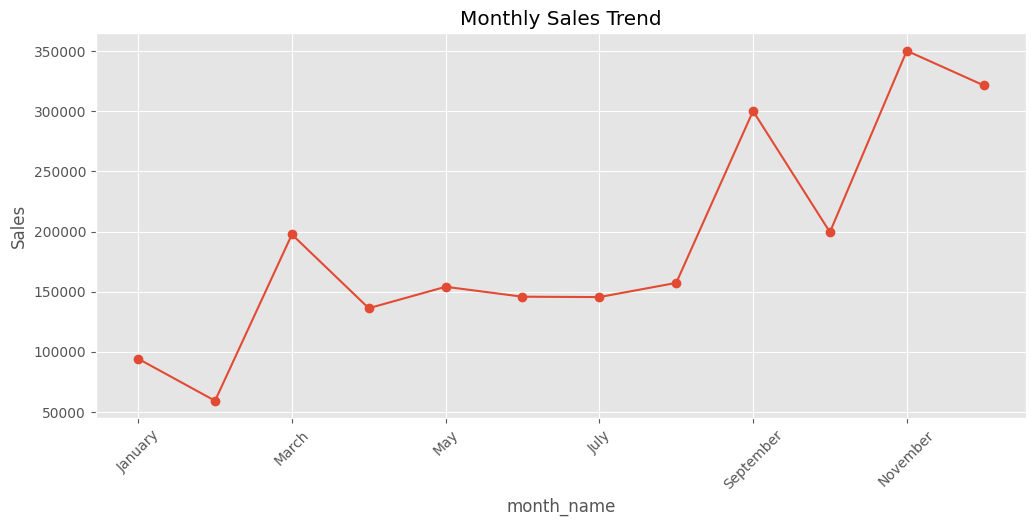

In [5]:
monthly_sales = (
    df.groupby("month_name")["sales"]
    .sum()
    .reindex([
        "January","February","March","April",
        "May","June","July","August",
        "September","October","November","December"
    ])
)

plt.figure(figsize=(12,5))

monthly_sales.plot(marker="o")

plt.title("Monthly Sales Trend")
plt.ylabel("Sales")
plt.xticks(rotation=45)

plt.show()

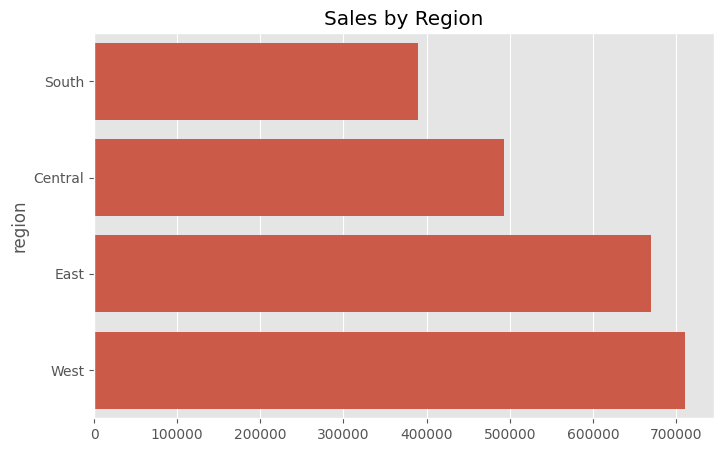

In [6]:
region_sales = (
    df.groupby("region")["sales"]
    .sum()
    .sort_values()
)

plt.figure(figsize=(8,5))

sns.barplot(
    x=region_sales.values,
    y=region_sales.index
)

plt.title("Sales by Region")

plt.show()

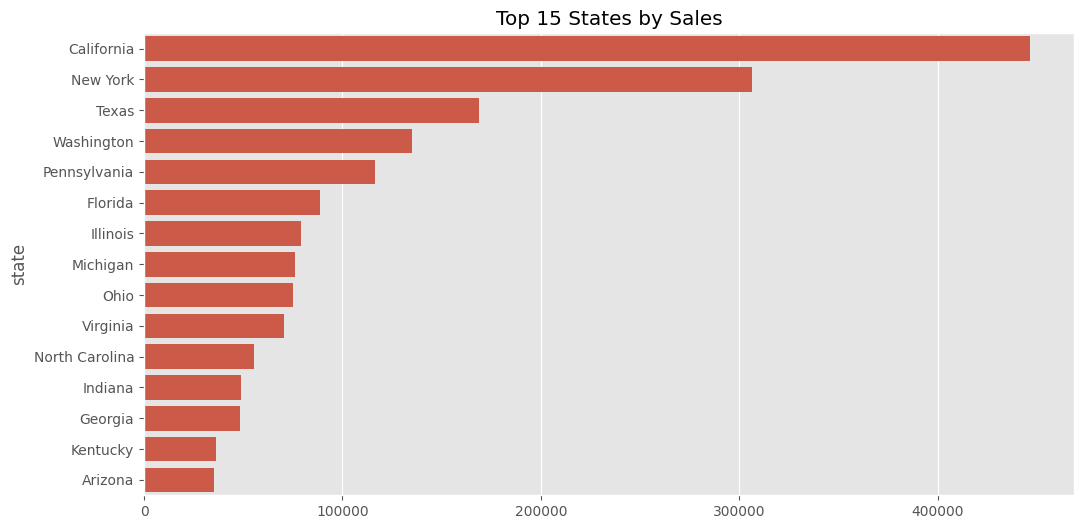

In [7]:
state_sales = (
    df.groupby("state")["sales"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=state_sales.values,
    y=state_sales.index
)

plt.title("Top 15 States by Sales")

plt.show()

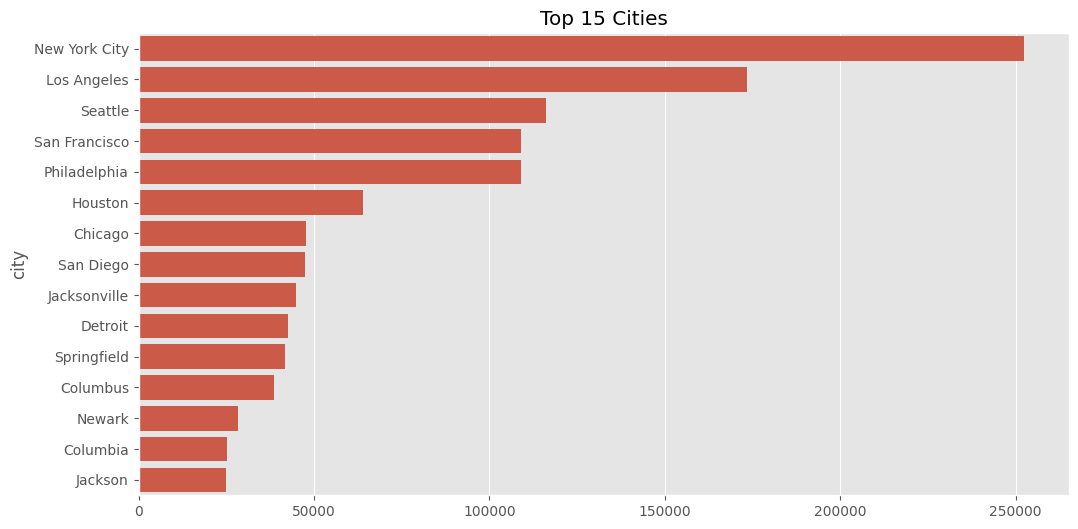

In [8]:
city_sales = (
    df.groupby("city")["sales"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=city_sales.values,
    y=city_sales.index
)

plt.title("Top 15 Cities")

plt.show()

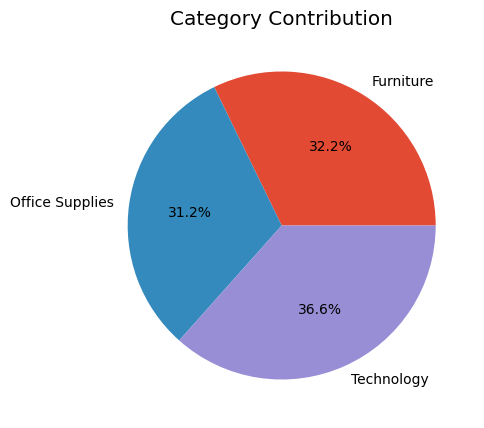

In [9]:
category_sales = (
    df.groupby("category")["sales"]
    .sum()
)

plt.figure(figsize=(8,5))

plt.pie(
    category_sales,
    labels=category_sales.index,
    autopct="%1.1f%%"
)

plt.title("Category Contribution")

plt.show()

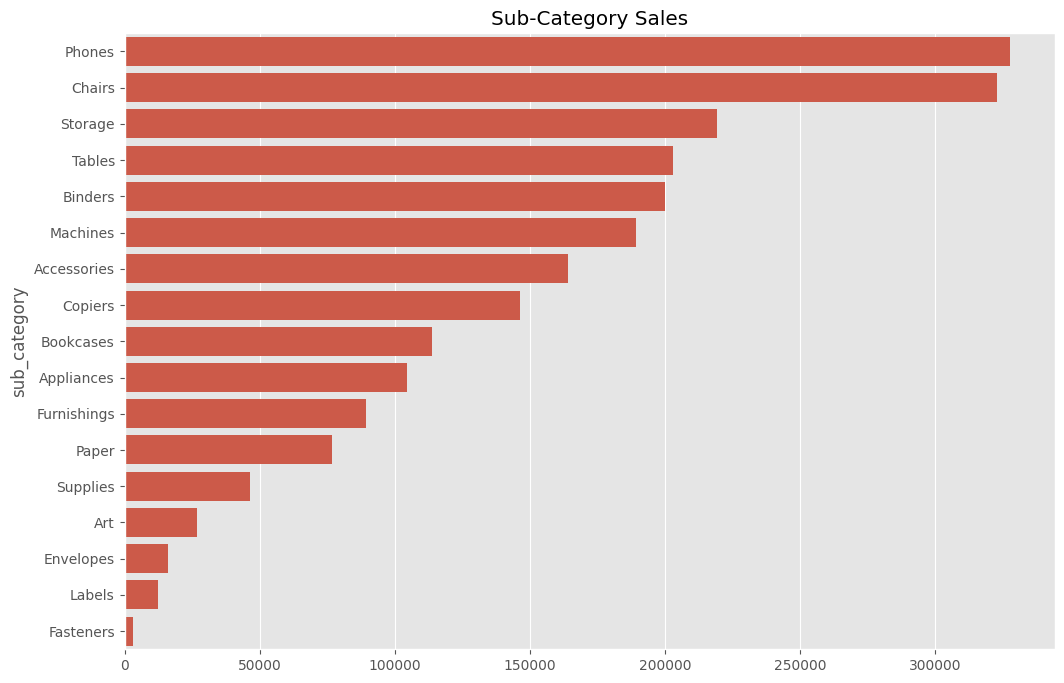

In [10]:
subcategory_sales = (
    df.groupby("sub_category")["sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12,8))

sns.barplot(
    x=subcategory_sales.values,
    y=subcategory_sales.index
)

plt.title("Sub-Category Sales")

plt.show()

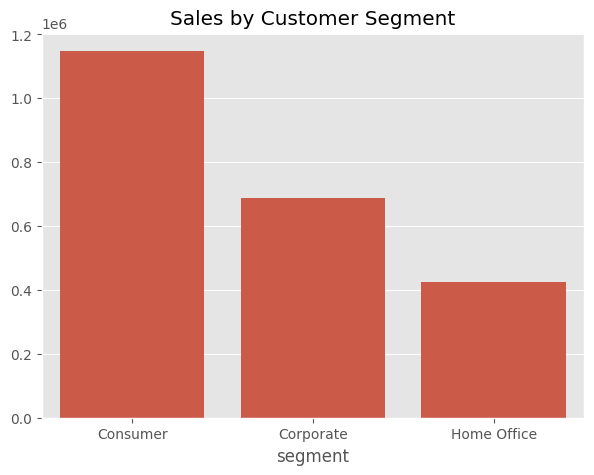

In [11]:
segment_sales = (
    df.groupby("segment")["sales"]
    .sum()
)

plt.figure(figsize=(7,5))

sns.barplot(
    x=segment_sales.index,
    y=segment_sales.values
)

plt.title("Sales by Customer Segment")

plt.show()

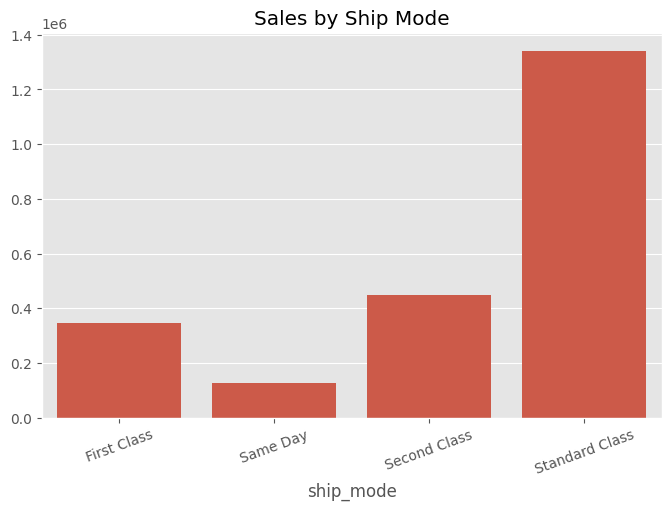

In [12]:
ship_sales = (
    df.groupby("ship_mode")["sales"]
    .sum()
)

plt.figure(figsize=(8,5))

sns.barplot(
    x=ship_sales.index,
    y=ship_sales.values
)

plt.xticks(rotation=20)

plt.title("Sales by Ship Mode")

plt.show()

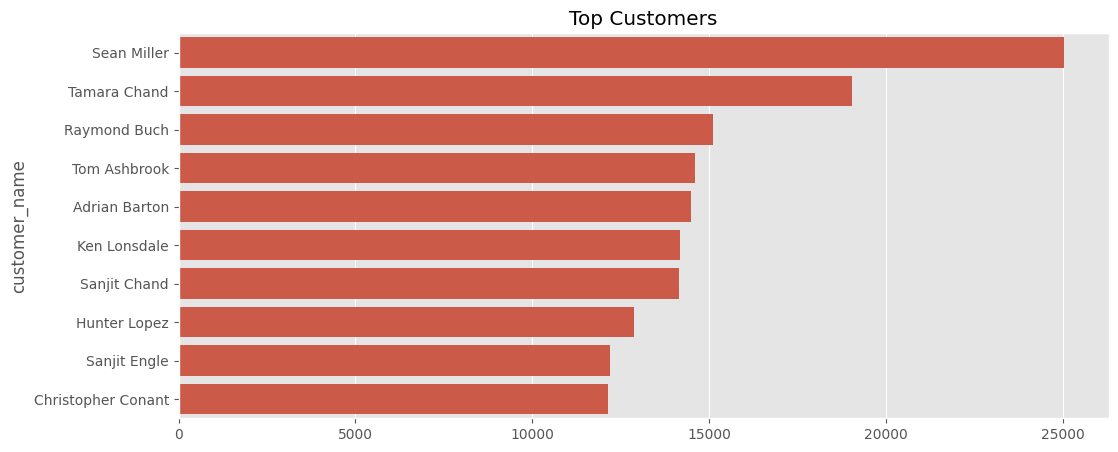

In [13]:
top_customers = (
    df.groupby("customer_name")["sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12,5))

sns.barplot(
    x=top_customers.values,
    y=top_customers.index
)

plt.title("Top Customers")

plt.show()

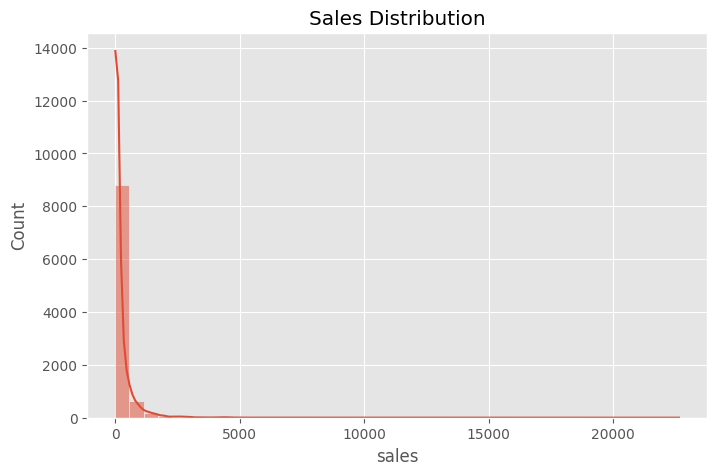

In [14]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["sales"],
    bins=40,
    kde=True
)

plt.title("Sales Distribution")

plt.show()

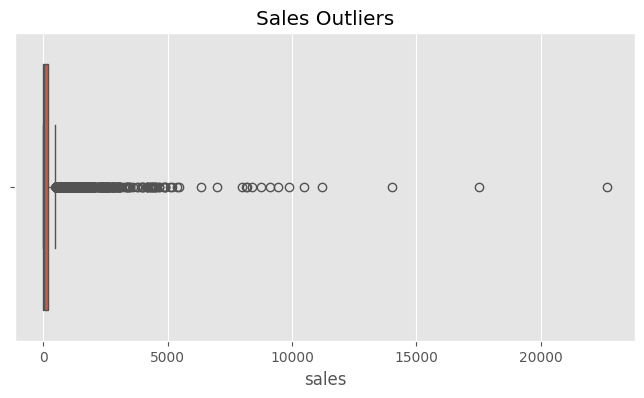

In [15]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df["sales"])

plt.title("Sales Outliers")

plt.show()

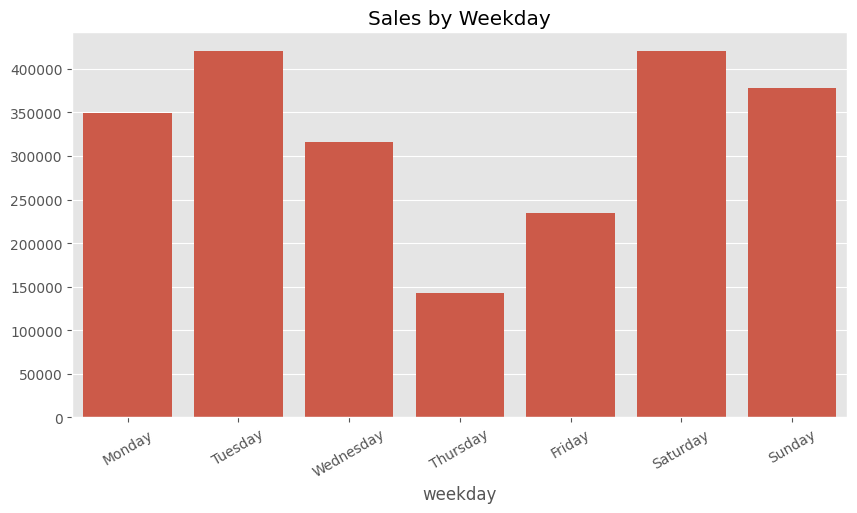

In [16]:
weekday_sales = (
    df.groupby("weekday")["sales"]
    .sum()
    .reindex([
        "Monday","Tuesday","Wednesday",
        "Thursday","Friday","Saturday","Sunday"
    ])
)

plt.figure(figsize=(10,5))

sns.barplot(
    x=weekday_sales.index,
    y=weekday_sales.values
)

plt.xticks(rotation=30)

plt.title("Sales by Weekday")

plt.show()

In [17]:
fig = px.treemap(
    df,
    path=["category","sub_category"],
    values="sales",
    color="sales",
    title="Category → Sub-Category Sales"
)

fig.show()

In [18]:
fig = px.sunburst(
    df,
    path=["region","state","category"],
    values="sales",
    title="Sales Hierarchy"
)

fig.show()

In [19]:
fig = px.scatter(
    df,
    x="shipping_days",
    y="sales",
    color="category",
    size="sales",
    hover_name="customer_name",
    title="Shipping Days vs Sales"
)

fig.show()

In [20]:
summary = (
    df.groupby("city")
    .agg(
        Total_Sales=("sales","sum"),
        Orders=("order_id","nunique"),
        Customers=("customer_id","nunique")
    )
    .sort_values("Total_Sales", ascending=False)
)

summary.head(20)

,Total_Sales,Orders,Customers
city,,,
New York City,252462.5470,439,349
Los Angeles,173420.1810,378,300
Seattle,116106.3220,210,187
San Francisco,109041.1200,261,230
Philadelphia,108841.7490,262,237
Houston,63956.1428,186,170
Chicago,47820.1330,166,150
San Diego,47521.0290,88,86
Jacksonville,44713.1830,61,61
